# EmotionSense AI — Basic Image Data Loading




In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Create a small sample dataset if no images are available




In [2]:
DATASET_DIR = Path("dataset_images")
DATASET_DIR.mkdir(parents=True, exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
existing_images = [
    p for p in DATASET_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
]

if not existing_images:
    # Create a few simple placeholder images so the notebook runs immediately.
    for i in range(1, 5):
        img = Image.new("RGB", (320, 240), (235, 235, 235))
        draw = ImageDraw.Draw(img)
        draw.rectangle((60, 35, 260, 205), outline=(70, 70, 70), width=3)
        draw.ellipse((105, 85, 125, 105), fill=(50, 50, 50))
        draw.ellipse((195, 85, 215, 105), fill=(50, 50, 50))
        draw.arc((120, 105, 200, 170), start=0, end=180, fill=(50, 50, 50), width=3)
        draw.text((12, 12), f"Sample image {i}", fill=(20, 20, 20))
        img.save(DATASET_DIR / f"sample_{i}.jpg")

image_paths = sorted(
    p for p in DATASET_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
)

print(f"Image folder: {DATASET_DIR.resolve()}")
print(f"Images found: {len(image_paths)}")

Image folder: /content/dataset_images
Images found: 4


## 2. Read image information

In [3]:
image_info = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            image_info.append({
                "filename": path.name,
                "width": img.width,
                "height": img.height,
                "format": img.format,
                "mode": img.mode
            })
    except Exception as error:
        print(f"Skipping unreadable file {path.name}: {error}")

image_df = pd.DataFrame(image_info)
display(image_df)

,filename,width,height,format,mode
0,sample_1.jpg,320,240,JPEG,RGB
1,sample_2.jpg,320,240,JPEG,RGB
2,sample_3.jpg,320,240,JPEG,RGB
3,sample_4.jpg,320,240,JPEG,RGB


## 3. Display sample images

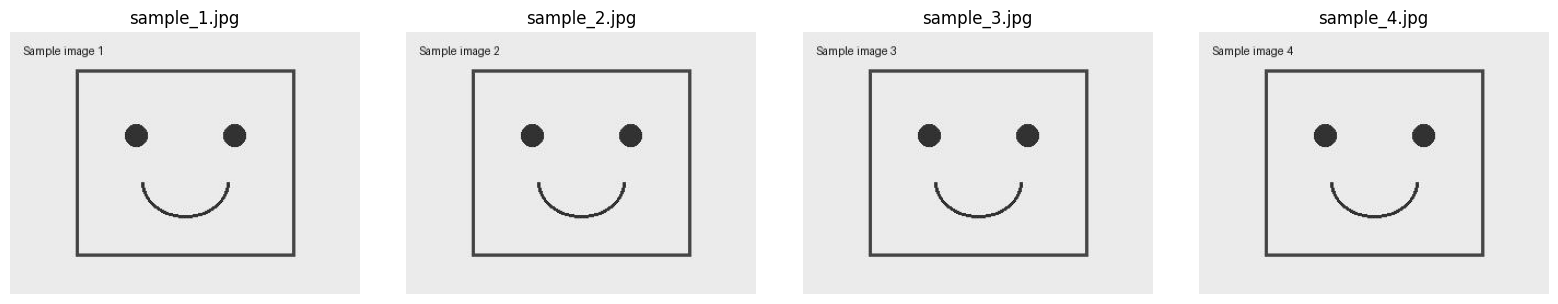

In [4]:
if image_paths:
    count = min(4, len(image_paths))
    fig, axes = plt.subplots(1, count, figsize=(4 * count, 3))
    if count == 1:
        axes = [axes]

    for ax, path in zip(axes, image_paths[:count]):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(path.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No image files are present yet.")

## 4. Resize and normalize images

Images are converted to RGB, resized to 224 × 224 pixels, and normalized to values between 0 and 1.

In [5]:
IMAGE_SIZE = (224, 224)

processed_images = []
processed_filenames = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            img = img.convert("RGB").resize(IMAGE_SIZE)
            array = np.asarray(img, dtype=np.float32) / 255.0

        processed_images.append(array)
        processed_filenames.append(path.name)
    except Exception as error:
        print(f"Skipping {path.name}: {error}")

X = np.stack(processed_images) if processed_images else np.empty(
    (0, IMAGE_SIZE[1], IMAGE_SIZE[0], 3), dtype=np.float32
)

print("Processed data shape:", X.shape)
print("Data type:", X.dtype)
if X.size:
    print("Pixel value range:", X.min(), "to", X.max())

Processed data shape: (4, 224, 224, 3)
Data type: float32
Pixel value range: 0.07450981 to 1.0


## 5. Save a simple image report

In [6]:
OUTPUT_DIR = Path("preprocessing_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

image_df.to_csv(OUTPUT_DIR / "image_report.csv", index=False)

print("Image report saved to:", (OUTPUT_DIR / "image_report.csv").resolve())
print("Notebook completed successfully.")

Image report saved to: /content/preprocessing_output/image_report.csv
Notebook completed successfully.
